# Chapitre 10 - Exercices 10.1 à 10.5

Ce notebook traite cinq exercices sur la construction de l'architecture (cours 1 et 2) :

- **10.1** : choisir et ordonner les composants pour trois applications (raisonnement + diagramme) ;
- **10.2** : étendre le masquage aux cartes bancaires avec la clé de Luhn (mini-lab) ;
- **10.3** : dimensionner une politique de relance : séquentielle, parallèle ou hybride (calcul + simulation) ;
- **10.4** : régler la règle de rejet d'un routeur d'intention et chiffrer ses erreurs (mini-lab) ;
- **10.5** : disponibilité d'une passerelle avec repli et dimensionnement d'un seau à jetons (calcul + simulation).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from aie.plotting import set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, COLORS, annotate_bars
from aie.diagrams import Diagram
from aie import llm
from aie import ch10_architecture as A

set_style()
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
embed = lambda texts: llm.embed(texts, llm.EMBED_MULTI)

## Exercice 10.1 : Choisir et ordonner les composants

**Énoncé.** Pour chacune des trois applications suivantes, indiquer quels composants de
l'architecture du chapitre sont nécessaires, avec une priorité de 0 (inutile) à 3
(indispensable dès la première version), et justifier. Dessiner ensuite l'architecture de
la troisième.

- **(a) Assistant RH interne** : 300 employés posent des questions sur les accords
  d'entreprise et leurs congés ; le modèle est **auto-hébergé** ; les documents sont internes.
- **(b) Chatbot d'e-commerce grand public** : 50 000 conversations par jour, une **API
  tierce**, beaucoup de questions répétitives (livraison, retours), un budget serré.
- **(c) Agent bancaire** : consulte les comptes et peut **initier des virements** pour les
  clients.

Composants : contexte (RAG), masquage des données personnelles, détection d'injection,
garde-fous de sortie, routeur, passerelle, cache exact, cache sémantique, boucle agentique,
actions d'écriture, observabilité.

**Rappels.** Section *AI Engineering Architecture* : on part de l'architecture minimale et
on ajoute un composant pour résoudre un problème observé. Le masquage protège surtout contre
l'envoi de données à une **API externe** (*Input guardrails*) ; le cache paie si le trafic est
**répétitif** (*Step 4*) ; les actions d'écriture exigent la plus grande prudence (*Step 5*) ;
l'observabilité est transversale (*Monitoring and Observability*).

**Solution.** Raisonnons composant par composant.

- **Contexte** : indispensable partout (accords d'entreprise, politique commerciale,
  comptes du client) : 3 / 3 / 3.
- **Masquage des données personnelles** : en (a), le modèle est auto-hébergé, les données ne
  sortent pas de l'organisation, le risque principal disparaît (1, pour les journaux) ; en (b)
  l'API est externe et les clients écrivent emails et téléphones : 3 ; en (c), IBAN et
  numéros de compte, avec obligations réglementaires : 3.
- **Injection** : (a) utilisateurs authentifiés et internes, risque modéré : 1 ; (b) public
  anonyme : 2 ; (c) un détournement peut déclencher un virement : 3.
- **Garde-fous de sortie** : 2 / 2 / 3 (en (c), toute action proposée doit être vérifiée).
- **Routeur** : (b) beaucoup de demandes ont une réponse type ou relèvent d'un humain
  (litiges), énorme levier de coût : 3 ; (a) 1 ; (c) 2 (séparer consultation et opérations).
- **Passerelle** : (b) API tierce, besoin de repli et de plafonnement des coûts : 2 ;
  (c) contrôle d'accès et traçabilité : 2 ; (a) un seul modèle : 0 au départ.
- **Cache exact** : (b) trafic très répétitif : 3 ; (a) 1 ; (c) réponses personnelles,
  risque de fuite : 0.
- **Cache sémantique** : (b) seulement après mesure du compromis : 1 ; (a) 0 ;
  (c) jamais (une erreur de cache donnerait le solde d'un autre client) : 0.
- **Boucle agentique** : (c) planifier « vérifier le solde, puis préparer le virement » : 2 ;
  1 / 1 ailleurs.
- **Actions d'écriture** : seulement (c), avec confirmation explicite et règles métier : 3.
- **Observabilité** : 2 / 3 / 3 (en (c), traçabilité exigée par l'audit).

L'ordre d'ajout suit la priorité : (b) commence par contexte + masquage + routeur + cache
exact, alors que (c) commence par contexte + tous les garde-fous + observabilité, et
n'ajoute les virements qu'en dernier.

**Vérification** graphique : la matrice des priorités, puis l'architecture de (c).

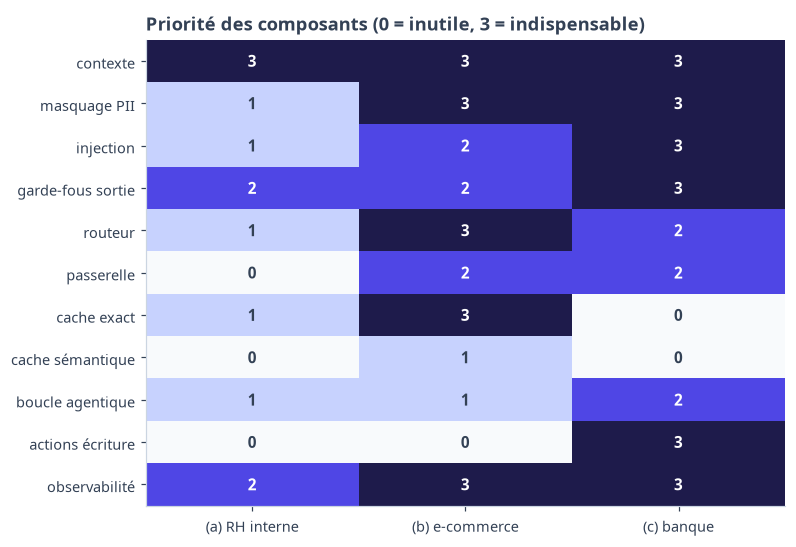

In [2]:
comps = ["contexte", "masquage PII", "injection", "garde-fous sortie", "routeur", "passerelle",
         "cache exact", "cache sémantique", "boucle agentique", "actions écriture", "observabilité"]
prio = pd.DataFrame({"(a) RH interne": [3, 1, 1, 2, 1, 0, 1, 0, 1, 0, 2],
                     "(b) e-commerce": [3, 3, 2, 2, 3, 2, 3, 1, 1, 0, 3],
                     "(c) banque": [3, 3, 3, 3, 2, 2, 0, 0, 2, 3, 3]}, index=comps)
fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.imshow(prio.values, cmap="aie_seq", vmin=0, vmax=3, aspect="auto"); ax.grid(False)
for i in range(len(comps)):
    for j in range(3):
        ax.text(j, i, prio.values[i, j], ha="center", va="center", color="white" if prio.values[i, j] >= 2 else SLATE,
                fontweight="bold")
ax.set_xticks(range(3), prio.columns); ax.set_yticks(range(len(comps)), comps)
ax.set_title("Priorité des composants (0 = inutile, 3 = indispensable)")
plt.show()

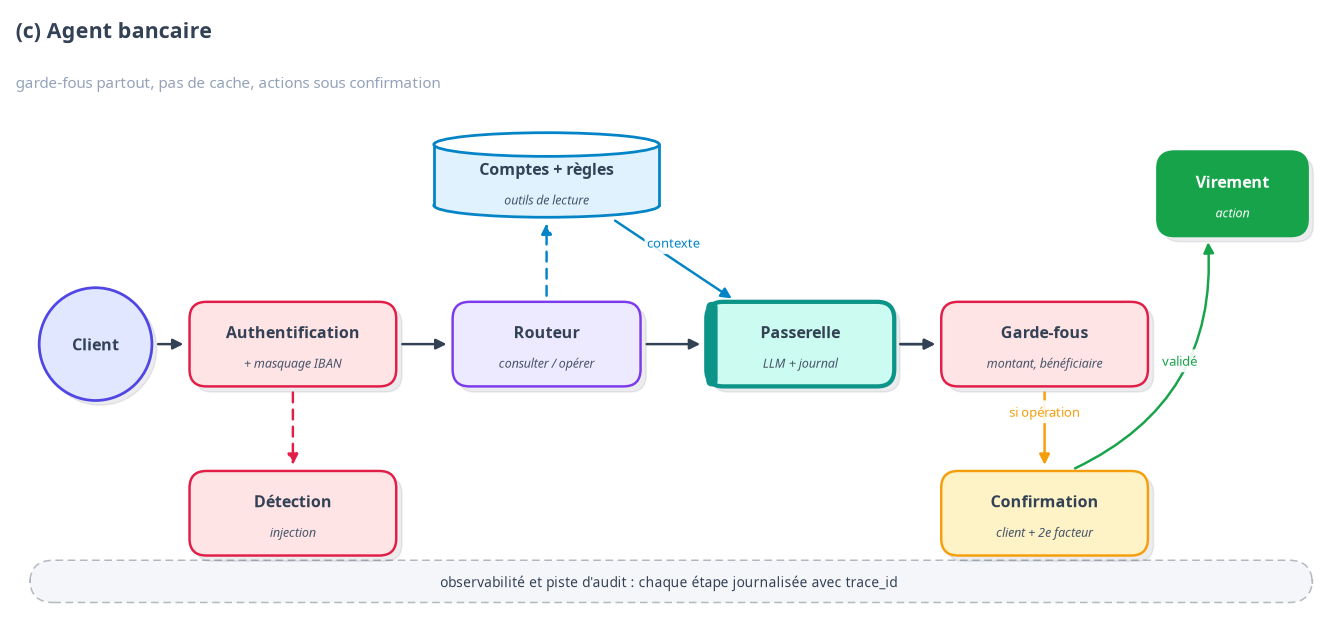

In [3]:
d = Diagram(14, 5.6, title="(c) Agent bancaire", subtitle="garde-fous partout, pas de cache, actions sous confirmation")
d.box("u", 0.9, 3.0, "Client", color=INDIGO, kind="user", w=1.2)
d.box("auth", 3.0, 3.0, "Authentification", sub="+ masquage IBAN", color=ROSE, w=2.2)
d.box("inj", 3.0, 1.2, "Détection", sub="injection", color=ROSE, w=2.2)
d.box("router", 5.7, 3.0, "Routeur", sub="consulter / opérer", color=VIOLET, w=2.0)
d.box("ctx", 5.7, 4.8, "Comptes + règles", sub="outils de lecture", color=SKY, kind="db", w=2.4)
d.box("llm", 8.4, 3.0, "Passerelle", sub="LLM + journal", color=TEAL, kind="model", w=2.0)
d.box("out", 11.0, 3.0, "Garde-fous", sub="montant, bénéficiaire", color=ROSE, w=2.2)
d.box("conf", 11.0, 1.2, "Confirmation", sub="client + 2e facteur", color=AMBER, w=2.2)
d.box("act", 13.0, 4.6, "Virement", sub="action", color=GREEN, w=1.6, filled=True)
d.arrow("u", "auth"); d.arrow("auth", "router"); d.arrow("auth", "inj", style="dashed", color=ROSE)
d.arrow("router", "llm"); d.arrow("ctx", "llm", "contexte", color=SKY); d.arrow("router", "ctx", color=SKY, style="dashed")
d.arrow("llm", "out"); d.arrow("out", "conf", "si opération", color=AMBER)
d.arrow("conf", "act", "validé", color=GREEN, rad=0.35)
d.arrow("llm", "out")
d.group(0.2, 0.25, 13.85, 0.7, None, color=SLATE)
d.note(7.0, 0.47, "observabilité et piste d'audit : chaque étape journalisée avec trace_id", color=SLATE, style="normal")
d.show()

> **À retenir.** Il n'existe pas d'architecture universelle : le mode d'hébergement (API ou
> auto-hébergé), la répétitivité du trafic et la gravité des actions déterminent quels
> composants ajouter et dans quel ordre.

## Exercice 10.2 : Masquer les numéros de carte bancaire (clé de Luhn)

**Énoncé.** (1) Ajouter aux détecteurs du cours une classe `CB` pour les numéros de carte
bancaire (16 chiffres, éventuellement groupés par 4). (2) Une regex seule produit des faux
positifs (numéros de suivi, références) : ajouter la validation par l'**algorithme de
Luhn** et montrer qu'un nombre aléatoire de 16 chiffres la passe avec probabilité 1/10.
(3) Montrer que Luhn détecte toute erreur sur un seul chiffre. (4) Mesurer précision et
rappel sur un petit jeu de messages, avec et sans validation.

**Rappels.** Section *Input guardrails* : les données personnelles (numéros d'identité,
téléphones, comptes bancaires) doivent être détectées puis bloquées ou masquées. Cours 1 : la
clé de contrôle de l'IBAN (modulo 97) réduit les faux positifs de la regex.

**Algorithme de Luhn.** En partant de la droite, on double un chiffre sur deux (le
2e, le 4e...) ; si le double dépasse 9, on soustrait 9 ; le numéro est valide si la somme de
tous les chiffres ainsi transformés est divisible par 10.

**Solution.** (2) Pour un nombre aléatoire, le dernier chiffre est uniforme et indépendant
des autres ; la somme modulo 10 vaut donc $(S' + d_{last}) \bmod 10$ avec $d_{last}$ uniforme
sur $\{0..9\}$ : exactement une valeur sur dix donne 0, d'où $P = 1/10$. La validation
divise donc les faux positifs par 10.

(3) Modifier un chiffre non doublé de $a$ en $b \ne a$ change la somme de $b - a \not\equiv 0
\pmod{10}$. Pour un chiffre doublé, la transformation $f(d) = 2d$ si $d \le 4$, $2d - 9$
sinon, donne $f(0..9) = 0,2,4,6,8,1,3,5,7,9$ : c'est une **permutation** de $\{0..9\}$, donc
$f(a) \ne f(b)$ et la somme change aussi. Toute erreur sur un chiffre est détectée.
$\blacksquare$

In [4]:
def luhn_ok(num: str) -> bool:
    digits = [int(c) for c in num if c.isdigit()][::-1]
    total = 0
    for i, dg in enumerate(digits):
        if i % 2 == 1:
            dg = 2 * dg - 9 if dg > 4 else 2 * dg
        total += dg
    return len(digits) in (15, 16) and total % 10 == 0

CB = r"\b(?:\d{4}[ -]?){3}\d{4}\b"
patterns_cb = {**A.PII_PATTERNS, "CB": CB}
patterns_cb = {"EMAIL": patterns_cb["EMAIL"], "IBAN": patterns_cb["IBAN"], "CB": CB, "TEL": patterns_cb["TEL"]}

def detect(text, validate=True):
    found = A.detect_pii(text, patterns_cb)
    return [m for m in found if m.kind != "CB" or not validate or luhn_ok(m.value)]

# (2) proportion de nombres aléatoires de 16 chiffres qui passent Luhn
rand16 = ["".join(map(str, rng.integers(0, 10, 16))) for _ in range(20000)]
p_pass = np.mean([luhn_ok(x) for x in rand16])
# (3) toutes les erreurs sur un chiffre d'un numéro valide
valid = "4970101234567893"
assert luhn_ok(valid)
errors = [valid[:i] + str(b) + valid[i + 1:] for i in range(16) for b in range(10) if str(b) != valid[i]]
print(f"(2) nombres aléatoires valides au sens de Luhn : {p_pass:.3f} (théorie 0,100)")
print(f"(3) erreurs d'un chiffre détectées : {np.mean([not luhn_ok(e) for e in errors]):.0%} sur {len(errors)}")

(2) nombres aléatoires valides au sens de Luhn : 0.096 (théorie 0,100)
(3) erreurs d'un chiffre détectées : 100% sur 144


**Vérification** (4) sur un jeu de messages annotés (numéros de test fictifs).

In [5]:
msgs = [
    ("Ma carte 4970 1012 3456 7893 a été débitée deux fois", {"4970 1012 3456 7893"}),
    ("Paiement refusé avec la carte 5132-8300-1234-5674", {"5132-8300-1234-5674"}),
    ("Numéro de suivi du colis : 1234 5678 9012 3456", set()),
    ("Référence commande 9876543210123456", set()),
    ("Carte 4970101234567893, expiration 12/27", {"4970101234567893"}),
    ("Ticket 1111 2222 3333 4444 au guichet", set()),
    ("J'ai tapé 4970 1012 3456 7894 par erreur", {"4970 1012 3456 7894"}),   # carte mal recopiée
    ("Code article 4000 0000 0000 0002", set()),
]
rows = []
for validate in [False, True]:
    vp = fp = fn = 0
    for t, gold in msgs:
        pred = {m.value for m in detect(t, validate) if m.kind == "CB"}
        vp += len(pred & gold); fp += len(pred - gold); fn += len(gold - pred)
    rows.append({"validation Luhn": validate, "VP": vp, "FP": fp, "FN": fn,
                 "précision": vp / max(vp + fp, 1), "rappel": vp / (vp + fn)})
res = pd.DataFrame(rows); display(res)
masked, rev = A.mask_pii(msgs[0][0], patterns_cb)
print("Masquage :", masked)

,validation Luhn,VP,FP,FN,précision,rappel
0,False,4,4,0,0.5,1.00
1,True,3,2,1,0.6,0.75


Masquage : Ma carte [CB_1] a été débitée deux fois


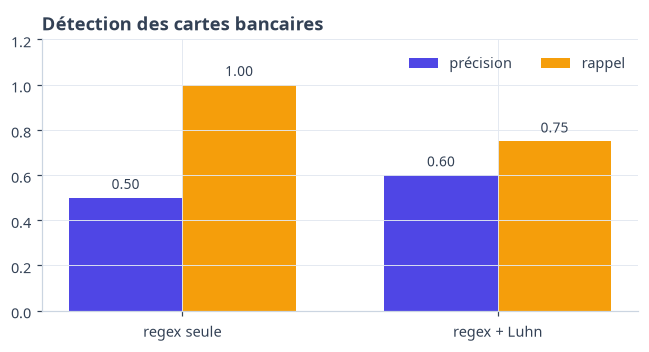

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(2)
ax.bar(x - 0.18, res["précision"], 0.36, color=INDIGO, label="précision")
ax.bar(x + 0.18, res["rappel"], 0.36, color=AMBER, label="rappel")
annotate_bars(ax, "{:.2f}"); ax.set_xticks(x, ["regex seule", "regex + Luhn"]); ax.set_ylim(0, 1.2)
ax.set_title("Détection des cartes bancaires"); ax.legend(ncol=2); plt.show()

La clé de Luhn élimine ici la moitié des faux positifs (numéro de suivi, référence) ; sur
des numéros quelconques elle en éliminerait neuf sur dix. Les deux qui restent ne sont pas
des hasards innocents : 1111 2222 3333 4444 et 4000 0000 0000 0002 sont des numéros de test
bien connus, construits pour avoir une clé correcte. Sur un si petit jeu, chaque cas pèse
lourd : il faut des centaines d'exemples pour estimer précision et rappel. En contrepartie, la carte **mal recopiée** n'est plus détectée : comme pour
l'IBAN, une donnée sensible erronée reste sensible. Une politique prudente consiste à
masquer tout ce qui a la forme d'une carte **dans les messages des clients** (rappel avant
tout) et à réserver la validation aux contextes où les faux positifs coûtent cher.

> **À retenir.** Les clés de contrôle (Luhn, modulo 97) divisent les faux positifs par 10
> ou 97 et détectent toute erreur d'un chiffre ; elles font aussi rater les numéros mal
> saisis : précision et rappel restent un arbitrage.

## Exercice 10.3 : Dimensionner une politique de relance

**Énoncé.** Un modèle produit un JSON valide avec probabilité $p = 0{,}85$ par appel ; un
appel dure 2 s et coûte 0,002 dollar. (1) Combien d'appels au maximum faut-il s'autoriser
pour garantir 99,9 % de succès ? (2) Pour une relance **séquentielle** avec ce plafond,
calculer le nombre moyen d'appels, la latence moyenne et la latence au 95e et au 99e
centile. (3) Même question pour une relance **parallèle** (tous les appels d'un coup).
(4) Proposer une stratégie **hybride** (2 appels parallèles, puis 2 autres si les deux
échouent) et la comparer. Vérifier par simulation.

**Rappels.** Section *Output guardrails* : relancer corrige beaucoup d'échecs mais ajoute
latence et coût ; lancer les appels en parallèle réduit la latence au prix d'appels
redondants. Cours 1 : $P(\text{succès}) = 1-(1-p)^n$ et nombre moyen d'appels séquentiels
$\frac{1-(1-p)^n}{p}$.

**Solution.** Notons $q = 1 - p = 0{,}15$.

(1) $q^n \le 10^{-3} \iff n \ge \ln 10^{-3} / \ln 0{,}15 = 3{,}64$, donc $n = 4$ appels
($P = 1 - 0{,}15^4 = 0{,}99949$).

(2) Séquentiel : $E[\text{appels}] = (1 - q^4)/p = 1{,}176$, soit une latence moyenne de
$2{,}35$ s et un coût de $0{,}00235$ dollar. Le $k$-ième appel n'a lieu qu'avec probabilité
$q^{k-1}$ : 85 % des requêtes finissent en 2 s, $1 - q^2 = 97{,}75$ % en 4 s, $1 - q^3 =
99{,}66$ % en 6 s. Donc **p95 = 4 s** et **p99 = 6 s**.

(3) Parallèle : latence 2 s pour tous (p95 = p99 = 2 s), mais 4 appels payés à chaque
fois : 0,008 dollar, soit 3,4 fois plus cher.

(4) Hybride : la première vague (2 appels) échoue avec probabilité $q^2 = 0{,}0225$. Latence :
2 s avec probabilité 0,9775, 4 s sinon, donc p95 = 2 s et p99 = 4 s ; appels moyens
$2 + 2 q^2 = 2{,}045$ ; succès $1 - q^4$ identique.

In [7]:
p, q, lat, cost = 0.85, 0.15, 2.0, 0.002
def simulate(strategy, n=200_000, seed=0):
    r = np.random.default_rng(seed)
    ok = r.random((n, 4)) < p                     # 4 tirages par requête
    if strategy == "séquentiel":
        first = np.where(ok.any(1), ok.argmax(1) + 1, 4)
        calls, latency = first, first * lat
    elif strategy == "parallèle":
        calls, latency = np.full(n, 4), np.full(n, lat)
    else:  # hybride 2 + 2
        wave1 = ok[:, :2].any(1)
        calls = np.where(wave1, 2, 4); latency = np.where(wave1, lat, 2 * lat)
    return {"succès": ok.any(1).mean(), "appels moyens": calls.mean(), "coût moyen ($)": calls.mean() * cost,
            "latence moyenne (s)": latency.mean(), "p95 (s)": np.percentile(latency, 95), "p99 (s)": np.percentile(latency, 99)}

sim = pd.DataFrame({s: simulate(s) for s in ["séquentiel", "parallèle", "hybride 2+2"]}).T
sim.round(4)

,succès,appels moyens,coût moyen ($),latence moyenne (s),p95 (s),p99 (s)
séquentiel,0.9995,1.1755,0.0024,2.3510,4.0,6.0
parallèle,0.9995,4.0000,0.0080,2.0000,2.0,2.0
hybride 2+2,0.9995,2.0445,0.0041,2.0445,2.0,4.0


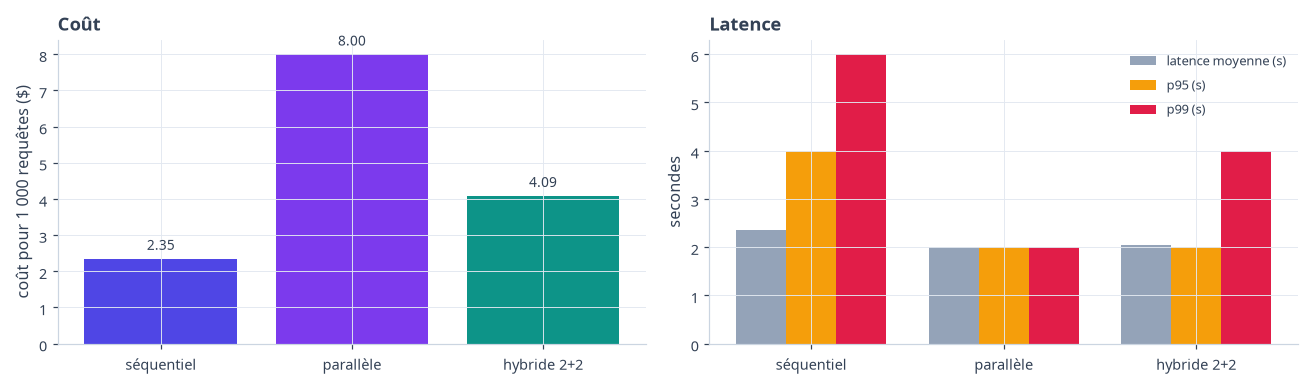

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
cols = [INDIGO, VIOLET, TEAL]
ax[0].bar(sim.index, sim["coût moyen ($)"] * 1000, color=cols); annotate_bars(ax[0], "{:.2f}")
ax[0].set(ylabel="coût pour 1 000 requêtes ($)", title="Coût")
xx = np.arange(3)
for j, (c, colr) in enumerate([("latence moyenne (s)", GRAY), ("p95 (s)", AMBER), ("p99 (s)", ROSE)]):
    ax[1].bar(xx + (j - 1) * 0.26, sim[c], 0.26, color=colr, label=c)
ax[1].set_xticks(xx, sim.index); ax[1].set(ylabel="secondes", title="Latence"); ax[1].legend(fontsize=8.5)
plt.tight_layout(); plt.show()

La simulation retrouve les valeurs calculées. L'hybride est un bon compromis : la latence
du parallèle pour 97,75 % des requêtes, pour un coût inférieur de moitié. Le bon choix
dépend de ce qui compte : un SLA sur le p99 pousse vers le parallèle, un budget serré vers
le séquentiel.

> **À retenir.** Les centiles de latence d'une relance séquentielle se lisent sur
> $1 - q^k$ ; paralléliser achète de la latence avec des appels redondants, et les
> stratégies hybrides se placent entre les deux.